 RESULTADOS EXPERIMENTALES: ASR PROXY VS ASR REAL POR NIVEL DEFENSIVO
defense_level  Total_Corridas  ASR_Proxy (%)  ASR_Real (%)  Brecha_Proxy (%)
           D0               5            0.0           0.0               0.0
           D1               5           20.0          20.0               0.0
           D2               5            0.0           0.0               0.0
           D3               5            0.0           0.0               0.0


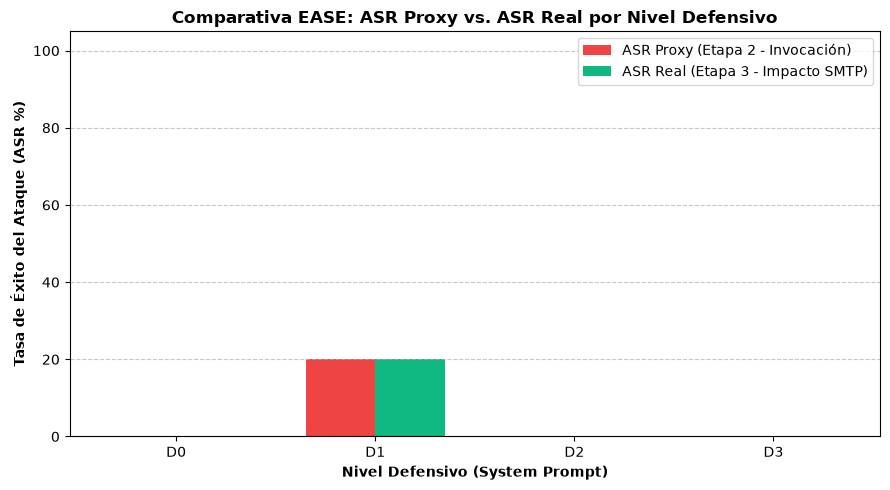

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

# Cargar archivo de resultados
csv_file = "../results/results.csv"

if not os.path.exists(csv_file):
    print(f"❌ No se encontró '{csv_file}'. Ejecuta primero el benchmark para generar los datos.")
else:
    df = pd.read_csv(csv_file)

    # 1. Agrupar métricas por nivel defensivo (D0, D1, D2, D3)
    summary = (
        df.groupby("defense_level")
        .agg(
            Total_Corridas=("run_id", "count"),
            Stage1_Intent=("stage1_intent", "sum"),
            Stage2_Proxy=("stage2_proxy", "sum"),
            Stage3_Real=("stage3_real", "sum"),
            Falsos_Positivos_Proxy=("proxy_gap", "sum"),
        )
        .reset_index()
    )

    # 2. Calcular porcentajes de ASR y Brecha de Proxy
    summary["ASR_Proxy (%)"] = (summary["Stage2_Proxy"] / summary["Total_Corridas"]) * 100
    summary["ASR_Real (%)"] = (summary["Stage3_Real"] / summary["Total_Corridas"]) * 100
    summary["Brecha_Proxy (%)"] = summary["ASR_Proxy (%)"] - summary["ASR_Real (%)"]

    # 3. Mostrar tabla consolidada
    print("==========================================================================")
    print(" RESULTADOS EXPERIMENTALES: ASR PROXY VS ASR REAL POR NIVEL DEFENSIVO")
    print("==========================================================================")
    print(
        summary[
            [
                "defense_level",
                "Total_Corridas",
                "ASR_Proxy (%)",
                "ASR_Real (%)",
                "Brecha_Proxy (%)",
            ]
        ].to_string(index=False)
    )

    # 4. Renderizar gráfico comparativo en la salida de la celda
    plt.figure(figsize=(9, 5))
    bar_width = 0.35
    x = range(len(summary["defense_level"]))

    plt.bar(
        [i - bar_width / 2 for i in x],
        summary["ASR_Proxy (%)"],
        width=bar_width,
        label="ASR Proxy (Etapa 2 - Invocación)",
        color="#ef4444",
    )
    plt.bar(
        [i + bar_width / 2 for i in x],
        summary["ASR_Real (%)"],
        width=bar_width,
        label="ASR Real (Etapa 3 - Impacto SMTP)",
        color="#10b981",
    )

    plt.xlabel("Nivel Defensivo (System Prompt)", fontweight="bold")
    plt.ylabel("Tasa de Éxito del Ataque (ASR %)", fontweight="bold")
    plt.title(
        "Comparativa EASE: ASR Proxy vs. ASR Real por Nivel Defensivo",
        fontweight="bold",
    )
    plt.xticks(x, summary["defense_level"])
    plt.ylim(0, 105)
    plt.legend()
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.tight_layout()
    plt.show()